# Architecture and response distributions (a-d)

Select the project `.venv` Python kernel and **Run All**. All panels are rebuilt from the copied YAML/CSV files in `data/figure_acbd`; no original figure is used as input.

Panels a/c show fixed A/B block connectivity examples. Coordinates are deterministic drawing layouts, not physical coordinates. Panel b uses 100,000 training and 2,000 independent Seed-43 test responses. Panel d uses 2,500 OOD responses with 6-10 blocks. The ordinate is `log10(chiN_star)`; internal lines mark quartiles. Violin KDE uses Scott bandwidth, `cut=0`, and area normalization, preserving the source settings and palette.

Outputs: `results/figures/figure_acbd/` contains PNG/SVG panels and the final PNG/SVG/PDF figure. Final SVG/PDF files contain raster panel images, following the manuscript composition; standalone panel SVG files retain vector paths and text. See the root `README.md` for environment and figure-reproduction instructions.

In [1]:
from pathlib import Path
import sys, subprocess, json
import numpy as np
import pandas as pd
from IPython.display import display, Image

cwd = Path.cwd().resolve()
CODE = next(p for base in (cwd, *cwd.parents) for p in (base, base / "sourcecode/code")
            if (p / "README.md").is_file() and (p / "notebooks").is_dir())
OUTPUT = CODE / "results/figures/figure_acbd"
print("Code:", CODE)
print("Python:", sys.executable)

Code: D:\2026\paper\TAPD\sourcecode\code
Python: D:\2026\paper\TAPD\.venv\Scripts\python.exe


In [2]:
# The figure scripts consume only the copied local architecture and response tables.
LOCAL_INPUTS = {
    "training": CODE / "data/figure_acbd/responses/training_100k_response_data.csv",
    "validation": CODE / "data/figure_acbd/responses/validation_seed43_2k_response_data.csv",
    "ood": CODE / "data/figure_acbd/responses/ood_6to10blocks_response_manifest.csv",
}
if not all(path.is_file() for path in LOCAL_INPUTS.values()):
    raise FileNotFoundError(LOCAL_INPUTS)
if not list((CODE / "data/figure_acbd/architecture").rglob("*.yml")):
    raise FileNotFoundError("No local architecture inputs found")

## Regenerate topology, distributions, and composition
Each script runs in a separate process to release high-resolution canvas memory.

In [ ]:
# Figure 2 plotting implementation (kept here as the single source of truth).
import os
import sys

STYLE_DIR = CODE / "src/plotting"
if str(STYLE_DIR) not in sys.path:
    sys.path.insert(0, str(STYLE_DIR))

_figure_scripts = [
    ('scripts\\figure_acbd\\redraw_ac_topologies_mpltex.py', '#!/usr/bin/env python3\n"""Redraw the Figure 2 a/c topology panels in the TAPD paper style."""\n\nfrom __future__ import annotations\n\nfrom pathlib import Path\nimport math\nimport sys\n\nimport matplotlib.pyplot as plt\nfrom matplotlib.lines import Line2D\nimport networkx as nx\nimport numpy as np\nimport yaml\n\n\nROOT = Path(__file__).resolve().parents[2]\nTRAIN_DATA = ROOT / "data/figure_acbd/architecture/train"\nOOD_DATA = ROOT / "data/figure_acbd/architecture/ood"\nOUT_STEM = ROOT / "results/figures/figure_acbd/ac_representative_topologies"\n\n\nfrom paper_style import (  # noqa: E402\n    TOPOLOGY_COLORS,\n    configure_paper_style,\n    draw_topology,\n    save_dual,\n)\n\n\n# Preserve the six training topologies used in the existing a panel.\nTRAIN_SAMPLES = [\n    "3blocks_sample_27020",\n    "3blocks_sample_01839",\n    "4blocks_sample_19583",\n    "5blocks_sample_12582",\n    "5blocks_sample_00369",\n    "5blocks_sample_04529",\n]\n\n# Preserve the five representative OOD samples selected for the existing c panel.\nOOD_SAMPLES = [\n    "6blocks_sample_00137",\n    "7blocks_sample_00203",\n    "8blocks_sample_00050",\n    "9blocks_sample_00005",\n    "10blocks_sample_00286",\n]\n\n\ndef load_blocks(directory: Path, stem: str) -> list[dict]:\n    with (directory / f"{stem}.yml").open(encoding="utf-8") as handle:\n        return yaml.safe_load(handle)["system"]["components"][0]["blocks"]\n\n\ndef graph_layout(blocks: list[dict]) -> dict[str, tuple[float, float]]:\n    graph = nx.Graph()\n    graph.add_edges_from(tuple(block["ends"]) for block in blocks)\n    raw = nx.kamada_kawai_layout(graph, weight=None)\n    nodes = sorted(raw)\n    points = np.asarray([raw[node] for node in nodes], dtype=float)\n    points -= points.mean(axis=0)\n    _, _, vh = np.linalg.svd(points, full_matrices=False)\n    points = points @ vh.T\n    if np.ptp(points[:, 0]) < np.ptp(points[:, 1]):\n        points = points[:, ::-1]\n    points[:, 0] /= max(np.max(np.abs(points[:, 0])), 1e-9)\n    points[:, 1] /= max(np.max(np.abs(points[:, 1])), 1e-9)\n    points[:, 1] *= 0.72\n    return {node: tuple(points[index]) for index, node in enumerate(nodes)}\n\n\ndef reference_a_layout(blocks: list[dict]) -> dict[str, tuple[float, float]]:\n    """Reproduce the deterministic tree layout used by the original a images."""\n    adjacency: dict[str, list[str]] = {}\n    for block in blocks:\n        n1, n2 = block["ends"]\n        adjacency.setdefault(n1, []).append(n2)\n        adjacency.setdefault(n2, []).append(n1)\n    root = max(sorted(adjacency), key=lambda node: len(adjacency[node]))\n    positions: dict[str, tuple[float, float]] = {root: (0.0, 0.0)}\n\n    def walk(node: str, parent: str | None, start: float, end: float, depth: int) -> None:\n        children = [child for child in adjacency[node] if child != parent]\n        if not children:\n            return\n        if len(children) == 1:\n            angles = [(start + end) / 2.0]\n        else:\n            step = (end - start) / max(1, len(children) - 1)\n            angles = [start + index * step for index in range(len(children))]\n        radius = 1.05 + 0.18 * depth\n        x0, y0 = positions[node]\n        for child, angle in zip(sorted(children), angles):\n            positions[child] = (x0 + radius * math.cos(angle),\n                                y0 + radius * math.sin(angle))\n            spread = max(math.pi / 5.0,\n                         (end - start) / max(2.4, len(children) + 1.0))\n            walk(child, node, angle - spread, angle + spread, depth + 1)\n\n    degree = len(adjacency[root])\n    initial_angles = [0.0] if degree <= 1 else [\n        2.0 * math.pi * index / degree for index in range(degree)\n    ]\n    for neighbor, angle in zip(sorted(adjacency[root]), initial_angles):\n        positions[neighbor] = (math.cos(angle), math.sin(angle))\n        walk(neighbor, root, angle - math.pi / 4.0, angle + math.pi / 4.0, 1)\n\n    points = np.asarray(list(positions.values()), dtype=float)\n    center = 0.5 * (points.min(axis=0) + points.max(axis=0))\n    points -= center\n    scale = max(np.max(np.abs(points[:, 0])), np.max(np.abs(points[:, 1])) / 0.72, 1e-9)\n    points /= scale\n    return {node: tuple(points[index]) for index, node in enumerate(positions)}\n\n\ndef draw_chain(\n    ax,\n    blocks: list[dict],\n    positions: dict[str, tuple[float, float]],\n    *,\n    reference_a: bool = False,\n) -> None:\n    # Small alternating bends reproduce the smooth, hand-drawn reference while\n    # retaining the exact graph connectivity and A/B identity of every block.\n    edges = []\n    for index, block in enumerate(blocks):\n        curvature = 0.16 if reference_a else 0.075 * (-1.0 if index % 2 else 1.0)\n        edges.append((*block["ends"], str(block["segment"]), curvature))\n\n    collection_start = len(ax.collections)\n    patch_start = len(ax.patches)\n    draw_topology(ax, positions, edges)\n\n    # The supplied reference is line-only: retain rounded paths, omit all nodes,\n    # and use the requested 5.8 pt line rather than the helper\'s standalone scale.\n    for patch in ax.patches[patch_start:]:\n        patch.set_linewidth(5.8)\n    for collection in list(ax.collections[collection_start:]):\n        collection.remove()\n\n    ax.set(xlim=(-1.18, 1.18), ylim=(-0.88, 0.88), aspect="equal")\n    ax.axis("off")\n\n\ndef add_grid_axes(fig, panel_bottom: float) -> list:\n    panel_left, panel_width, panel_height = 0.10, 0.865, 0.427\n    gap_x, gap_y = 0.018, 0.035\n    cell_width = (panel_width - 2 * gap_x) / 3\n    cell_height = (panel_height - gap_y) / 2\n    axes = []\n    for index in range(6):\n        row, col = divmod(index, 3)\n        left = panel_left + col * (cell_width + gap_x)\n        bottom = panel_bottom + (1 - row) * (cell_height + gap_y)\n        axes.append(fig.add_axes([left, bottom, cell_width, cell_height]))\n    return axes\n\n\ndef main() -> None:\n    configure_paper_style()\n    # Exactly match the current b/d canvas: 12 x 16.2 in at 600 dpi = 7200 x 9720 px.\n    fig = plt.figure(figsize=(12.0, 16.2), facecolor="white")\n    axes_a = add_grid_axes(fig, panel_bottom=0.553)\n    axes_c = add_grid_axes(fig, panel_bottom=0.100)\n\n    for ax, stem in zip(axes_a, TRAIN_SAMPLES):\n        blocks = load_blocks(TRAIN_DATA, stem)\n        draw_chain(ax, blocks, reference_a_layout(blocks), reference_a=True)\n\n    for ax, stem in zip(axes_c[:5], OOD_SAMPLES):\n        blocks = load_blocks(OOD_DATA, stem)\n        draw_chain(ax, blocks, graph_layout(blocks))\n\n    # The sixth c-panel cell is intentionally reserved for the sole A/B legend.\n    legend_ax = axes_c[5]\n    legend_ax.axis("off")\n    handles = [\n        Line2D([0], [0], color=TOPOLOGY_COLORS["A"], lw=5.8,\n               solid_capstyle="round", label="A block"),\n        Line2D([0], [0], color=TOPOLOGY_COLORS["B"], lw=5.8,\n               solid_capstyle="round", label="B block"),\n    ]\n    legend_ax.legend(handles=handles, loc="lower right", frameon=False,\n                     fontsize=24, handlelength=2.3, handletextpad=0.7,\n                     bbox_to_anchor=(1.0, 0.20), borderaxespad=0.0,\n                     labelspacing=0.75)\n\n    save_dual(fig, OUT_STEM, tight=False)\n    plt.close(fig)\n    print(f"Saved {OUT_STEM}.png/.svg")\n\n\nif __name__ == "__main__":\n    main()\n'),
    ('scripts\\figure_acbd\\redraw_bd_violin_seed43_mpltex.py', '#!/usr/bin/env python3\n"""Redraw only panels b/d; panels a/c remain untouched in the master artwork."""\n\nfrom __future__ import annotations\n\nimport os\nimport sys\nfrom pathlib import Path\n\n\n\nROOT = Path(__file__).resolve().parents[2]\n\n\nimport matplotlib.pyplot as plt\nimport numpy as np\nimport pandas as pd\nimport seaborn as sns\nimport yaml\nfrom matplotlib.patches import Patch\nfrom matplotlib.ticker import MultipleLocator\n\nfrom paper_style import configure_paper_style, save_dual, style_distribution_axis\n\n\nTRAIN_TABLE = ROOT / "data/figure_acbd/responses/training_100k_response_data.csv"\nTEST_TABLE = ROOT / "data/figure_acbd/responses/validation_seed43_2k_response_data.csv"\nOOD_MANIFEST = ROOT / "data/figure_acbd/responses/ood_6to10blocks_response_manifest.csv"\nOUT_STEM = ROOT / "results/figures/figure_acbd/bd_response_distributions"\n\n# Preserve the reference palette exactly.\nTRAIN_COLOR, TEST_COLOR, OOD_COLOR = "#4C78A8", "#F58518", "#54A24B"\n\n\ndef load_test() -> pd.DataFrame:\n    frame = pd.read_csv(TEST_TABLE, usecols=["n_blocks", "log10_chiN_star"])\n    frame["dataset"] = "Test"\n    if len(frame) != 2000:\n        raise RuntimeError(f"Expected 2,000 seed43 independent test samples, found {len(frame)}.")\n    return frame\n\n\ndef draw(\n    ax,\n    frame: pd.DataFrame,\n    blocks: list[int],\n    palette: dict[str, str],\n    split: bool,\n    ylim: tuple[float, float],\n) -> None:\n    labels = [f"{n} blocks" for n in blocks]\n    frame = frame.copy()\n    frame["block_label"] = pd.Categorical(\n        frame["n_blocks"].map(lambda n: f"{n} blocks"), categories=labels, ordered=True\n    )\n    sns.violinplot(\n        data=frame, x="block_label", y="log10_chiN_star", hue="dataset",\n        order=labels, hue_order=list(palette), palette=palette, split=split,\n        inner="quartile", cut=0, density_norm="area", common_norm=False,\n        linewidth=2.0, saturation=1, ax=ax,\n    )\n    ax.set(xlabel="", ylabel=r"$\\log_{10}(\\chi N^*)$", ylim=ylim)\n    ax.set_yticks(np.arange(1.0, 3.01, 0.5))\n    ax.yaxis.set_minor_locator(MultipleLocator(0.25))\n    ax.set_ylabel(r"$\\log_{10}(\\chi N^*)$", fontsize=30)\n    # Matplotlib expresses box aspect as height / width: 2 / 3 gives 3:2.\n    ax.set_box_aspect(2.0 / 3.0)\n    style_distribution_axis(ax)\n    # Keep the frame and internal quartile lines at the 2.8 pt reference\n    # stroke, while using the requested 2.0 pt violin outlines.\n    for spine in ax.spines.values():\n        spine.set_linewidth(2.8)\n    for collection in ax.collections:\n        collection.set_linewidth(2.0)\n        collection.set_edgecolor("#333333")\n    for line in ax.lines:\n        line.set_linewidth(2.8)\n    ax.tick_params(which="major", labelsize=24)\n    ax.grid(False)\n    if ax.get_legend() is not None:\n        ax.get_legend().remove()\n\n\ndef save_single_panel(\n    frame: pd.DataFrame,\n    blocks: list[int],\n    palette: dict[str, str],\n    split: bool,\n    ylim: tuple[float, float],\n    legend_handles: list[Patch],\n    stem: Path,\n) -> None:\n    """Export a standalone panel for lossless a--d composition."""\n    fig, ax = plt.subplots(figsize=(12.0, 8.1), facecolor="white")\n    draw(ax, frame, blocks, palette, split=split, ylim=ylim)\n    ax.legend(handles=legend_handles, loc="upper left", frameon=False, fontsize=24,\n              ncol=len(legend_handles), handlelength=1.8, handleheight=1.0,\n              columnspacing=1.0)\n    fig.subplots_adjust(left=0.10, right=0.965, bottom=0.13, top=0.96)\n    fig.text(0.5325, 0.045, "Number of blocks", ha="center", va="center", fontsize=30)\n    save_dual(fig, stem, tight=False)\n    plt.close(fig)\n\n\ndef main() -> None:\n    configure_paper_style()\n    train = pd.read_csv(TRAIN_TABLE, usecols=["n_blocks", "log10_chiN_star"])\n    train["dataset"] = "Train"\n    test = load_test()\n    ood = pd.read_csv(OOD_MANIFEST, usecols=["block_count", "log10_chiN_star"])\n    ood = ood.rename(columns={"block_count": "n_blocks"})\n    ood["dataset"] = "OOD test"\n\n    # Two stacked 12 x 8-inch reference-sized panels.  These margins give\n    # each axes box approximately 10.4 x 6.9 inches (width:height = 3:2),\n    # matching the supplied 7185 x 4813 px reference at 600 dpi.\n    fig, (ax_b, ax_d) = plt.subplots(2, 1, figsize=(12.0, 16.2), facecolor="white")\n    draw(ax_b, pd.concat([train, test], ignore_index=True), [2, 3, 4, 5],\n         {"Train": TRAIN_COLOR, "Test": TEST_COLOR}, split=True,\n         ylim=(0.875, 3.25))\n    draw(ax_d, ood, [6, 7, 8, 9, 10], {"OOD test": OOD_COLOR}, split=False,\n         ylim=(0.875, 3.125))\n    ax_b.legend(\n        handles=[Patch(facecolor=TRAIN_COLOR, edgecolor="none", label="Train"),\n                 Patch(facecolor=TEST_COLOR, edgecolor="none", label="Test")],\n        loc="upper left", ncol=2, frameon=False, fontsize=24,\n        handlelength=1.8, handleheight=1.0, columnspacing=1.0,\n    )\n    ax_d.legend(\n        handles=[Patch(facecolor=OOD_COLOR, edgecolor="none", label="OOD test")],\n        loc="upper left", frameon=False, fontsize=24,\n        handlelength=1.8, handleheight=1.0,\n    )\n    fig.subplots_adjust(left=0.10, right=0.965, bottom=0.10, top=0.98, hspace=0.06)\n    # Centre the shared label on the actual axes boxes, not on the full canvas.\n    fig.canvas.draw()\n    lower_box = ax_d.get_position()\n    axes_center = 0.5 * (lower_box.x0 + lower_box.x1)\n    fig.text(axes_center, 0.035, "Number of blocks", ha="center", va="center", fontsize=30)\n    save_dual(fig, OUT_STEM, tight=False)\n    plt.close(fig)\n    save_single_panel(\n        pd.concat([train, test], ignore_index=True), [2, 3, 4, 5],\n        {"Train": TRAIN_COLOR, "Test": TEST_COLOR}, True, (0.875, 3.25),\n        [Patch(facecolor=TRAIN_COLOR, edgecolor="none", label="Train"),\n         Patch(facecolor=TEST_COLOR, edgecolor="none", label="Test")],\n        ROOT / "results/figures/figure_acbd/panel_b_response_distribution",\n    )\n    save_single_panel(\n        ood, [6, 7, 8, 9, 10], {"OOD test": OOD_COLOR}, False, (0.875, 3.125),\n        [Patch(facecolor=OOD_COLOR, edgecolor="none", label="OOD test")],\n        ROOT / "results/figures/figure_acbd/panel_d_response_distribution",\n    )\n    print(f"Saved {OUT_STEM}.png/.svg")\n\n\nif __name__ == "__main__":\n    main()\n'),
    ('scripts\\figure_acbd\\compose_acbd_four_panel.py', '"""Compose the mpltex topology and violin columns into manuscript Figure 2."""\n\nfrom pathlib import Path\nimport sys\n\nimport matplotlib as mpl\n\nmpl.use("Agg")\n\nimport matplotlib.pyplot as plt\nimport numpy as np\nfrom PIL import Image\n\n\n\nfrom paper_style import configure_paper_style, save_dual  # noqa: E402\n\n\nconfigure_paper_style()\n\n\ndef trim_white_margin(image: Image.Image, *, padding: int = 90) -> Image.Image:\n    pixels = np.asarray(image.convert("RGB"))\n    ink = np.any(pixels < 248, axis=2)\n    if not ink.any():\n        return image\n    rows, columns = np.where(ink)\n    left = max(0, int(columns.min()) - padding)\n    top = max(0, int(rows.min()) - padding)\n    right = min(image.width, int(columns.max()) + padding + 1)\n    bottom = min(image.height, int(rows.max()) + padding + 1)\n    return image.crop((left, top, right, bottom))\n\n\ndef main() -> None:\n    source_root = Path(__file__).resolve().parents[2] / "results/figures/figure_acbd"\n    topology_path = source_root / "ac_representative_topologies.png"\n    violin_path = source_root / "bd_response_distributions.png"\n\n    topology = Image.open(topology_path).convert("RGB")\n    violin = Image.open(violin_path).convert("RGB")\n    if topology.size != violin.size:\n        raise ValueError(f"Source columns must have equal dimensions: {topology.size} != {violin.size}")\n\n    topology = trim_white_margin(topology)\n    violin = trim_white_margin(violin)\n\n    fig = plt.figure(figsize=(15.2, 10.2), facecolor="white")\n    grid = fig.add_gridspec(1, 2, left=0.018, right=0.995, bottom=0.018, top=0.988,\n                            wspace=0.012, width_ratios=(1, 1))\n    axes = [fig.add_subplot(grid[0, index]) for index in range(2)]\n    for axis, panel in zip(axes, (topology, violin)):\n        axis.imshow(panel, interpolation="lanczos")\n        axis.set_axis_off()\n\n    # Match the supplied reference: bold parenthesized labels outside panel content.\n    label_style = dict(fontsize=32, fontweight="bold", ha="left", va="top", color="black")\n    fig.text(0.002, 0.998, "(a)", **label_style)\n    fig.text(0.500, 0.998, "(b)", **label_style)\n    fig.text(0.002, 0.505, "(c)", **label_style)\n    fig.text(0.500, 0.505, "(d)", **label_style)\n\n    output = source_root / "figure_acbd_four_panel"\n    png, svg = save_dual(fig, output, tight=False)\n    fig.savefig(output.with_suffix(".pdf"), dpi=600, facecolor="white")\n    plt.close(fig)\n\n    if not png.is_file() or not svg.is_file():\n        raise RuntimeError("Figure 2 export failed")\n\n\nif __name__ == "__main__":\n    main()\n'),

]
for relative_name, source in _figure_scripts:
    virtual_file = CODE / relative_name
    namespace = {"__file__": str(virtual_file), "__name__": "__main__"}
    exec(compile(source, str(virtual_file), "exec"), namespace)
    print("Completed:", relative_name)

for extension in ("png", "svg", "pdf"):
    output_path = OUTPUT / f"figure_acbd_four_panel.{extension}"
    assert output_path.is_file() and output_path.stat().st_size > 0, output_path
print("All Figure 2 panels regenerated.")



Export pixels: (9120, 6120) DPI: (599.9988, 599.9988)


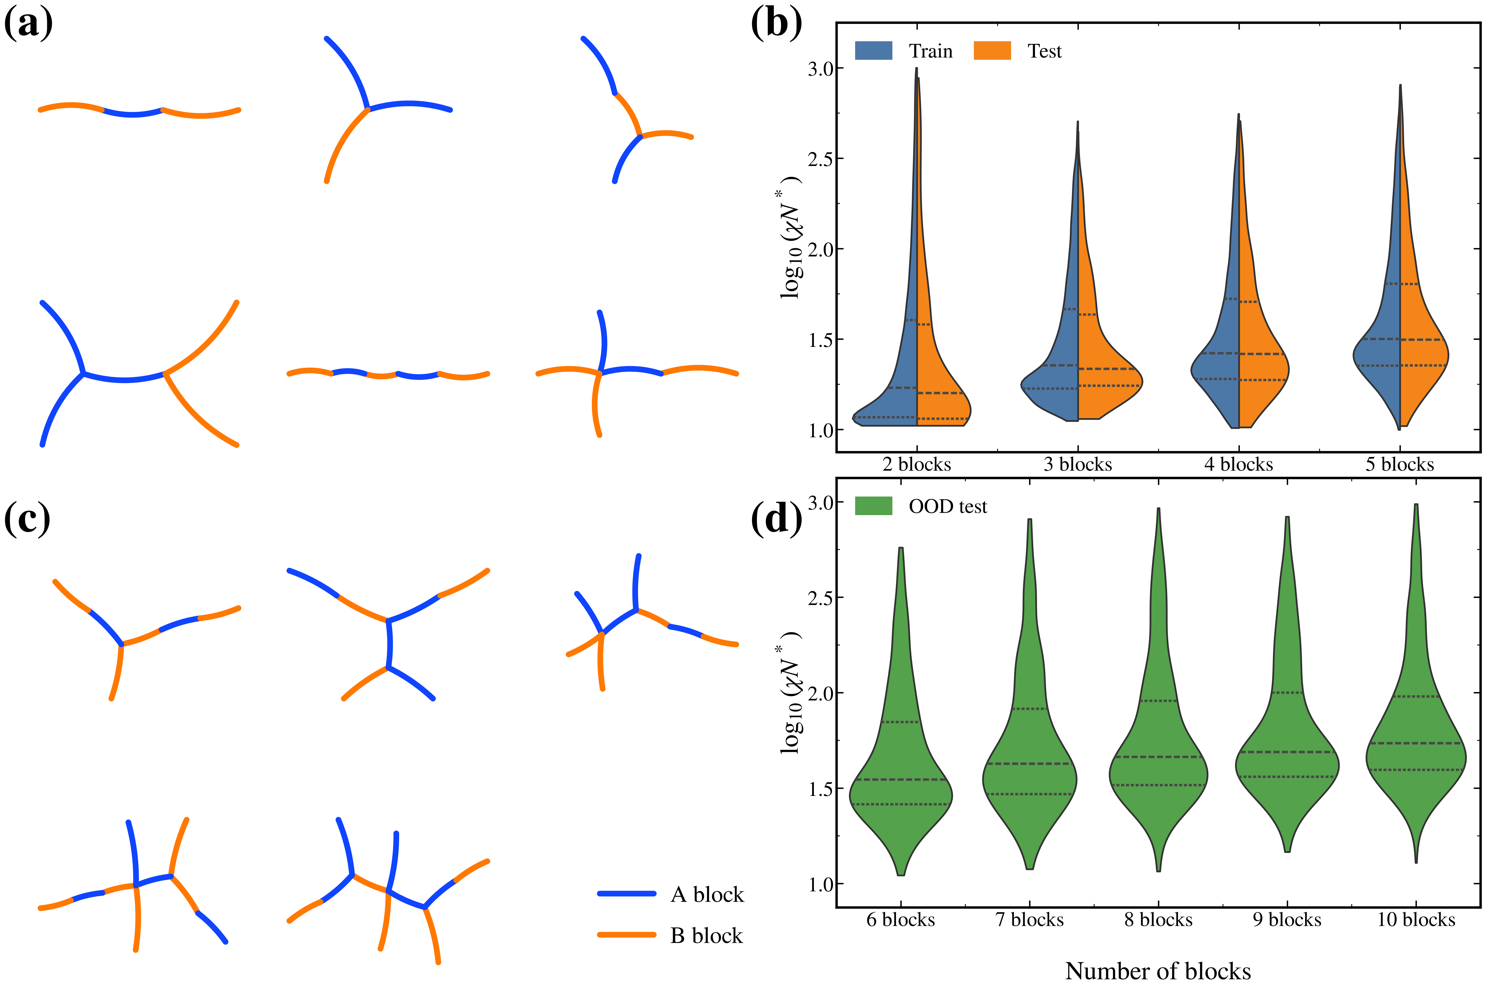

{'matplotlib': '3.11.1',
 'seaborn': '0.13.2',
 'numpy': '2.5.3',
 'pandas': '3.0.5',
 'scipy': '1.18.1',
 'networkx': '3.6.1',
 'PyYAML': '6.0.3',
 'Pillow': '12.3.0',
 'nbformat': '5.11.1',
 'nbclient': '0.11.0',
 'ipykernel': '7.3.0'}

In [4]:
# Embed a compact preview; full-resolution export stays on disk.
from PIL import Image as PILImage
from io import BytesIO
with PILImage.open(OUTPUT / "figure_acbd_four_panel.png") as img:
    print("Export pixels:", img.size, "DPI:", img.info.get("dpi"))
    img.thumbnail((1500, 1100))
    buffer = BytesIO()
    img.save(buffer, format="PNG")
display(Image(data=buffer.getvalue()))
import importlib.metadata as metadata
versions = {name: metadata.version(name) for name in
            ("matplotlib", "seaborn", "numpy", "pandas", "scipy", "networkx", "PyYAML", "Pillow", "nbformat", "nbclient", "ipykernel")}
(OUTPUT / "environment.json").write_text(json.dumps(versions, indent=2))
versions